<a href="https://colab.research.google.com/github/mercygerman/MODULE_2_CASE_EXERCISE-_1/blob/main/MOULDE__2__CASE__EXERCISE__1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

QUESTION 1

Implement the pressure_temperature_envelope() function from Section 2.2.2 with full documentation and error handling.


P-T envelope calculated successfully.
Minimum pressure: 500.0 psi
Maximum pressure: 4467.0 psi
Seabed reference temperature: 4.0 °C
Maximum temperature limit: 82.0 °C
Hydrate safety margin: 5.0 °C
Number of pressure points: 100
The calculated temperature boundary stays within the specified maximum temperature.


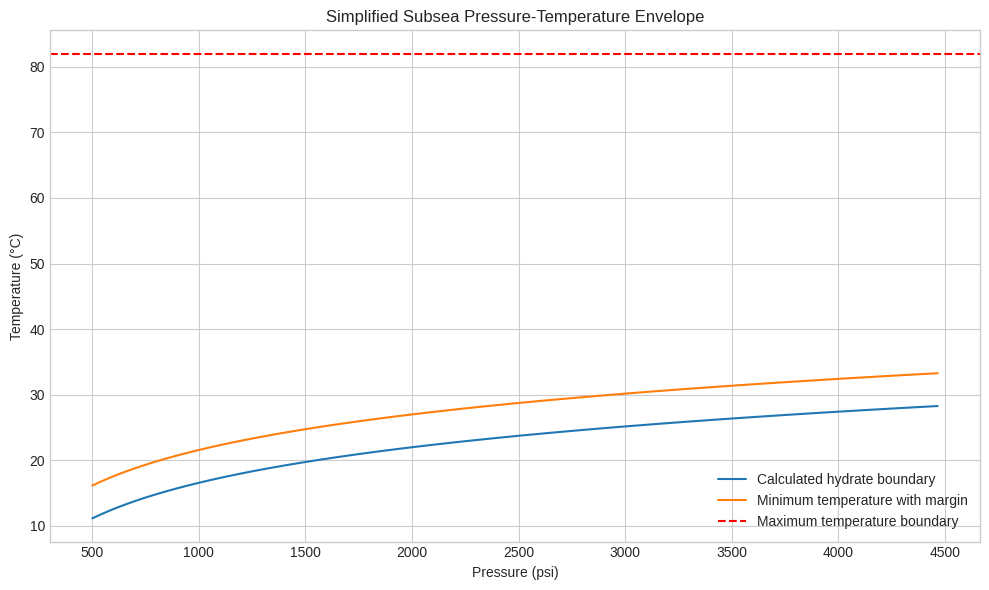

In [29]:
import numpy as np
import matplotlib.pyplot as plt
import math


def pressure_temperature_envelope(
    p_max: float = 4467.0,
    p_min: float = 500.0,
    t_min_seabed: float = 4.0,
    t_max_reservoir: float = 82.0,
    hydrate_offset: float = 5.0,
) -> dict:
    """
    Construct a simplified pressure-temperature (P-T) envelope
    for a subsea production system.

    Parameters
    ----------
    p_max : float, default=4467.0
        Maximum design pressure in psi.

    p_min : float, default=500.0
        Minimum pressure considered in psi. The value represents
        a supplied operating threshold and must be verified against
        the approved engineering design basis.

    t_min_seabed : float, default=4.0
        Seabed reference temperature in degrees Celsius.

    t_max_reservoir : float, default=82.0
        Maximum temperature boundary in degrees Celsius.

    hydrate_offset : float, default=5.0
        Temperature margin added to the calculated hydrate curve,
        in degrees Celsius. This is a simplified screening margin.

    Returns
    -----
    dict
        A dictionary containing:
        - pressures: Array of pressure values in psi.
        - t_hydrate: Calculated hydrate-boundary temperatures.
        - t_safe_min: Hydrate temperatures plus the safety margin.
        - p_max: Maximum pressure limit.
        - p_min: Minimum pressure limit.
        - t_min_seabed: Seabed reference temperature.
        - t_max: Maximum temperature limit.
        - hydrate_offset: Applied temperature margin.
        - within_temperature_limit: Boolean array indicating where
          the calculated minimum temperature does not exceed t_max.

    Raises
    ------
    TypeError
        If an input is missing or is not a real number.
        Boolean values are not accepted as numbers.

    ValueError
        If an input is not finite, pressures are invalid,
        the temperature limits are inconsistent, or the
        hydrate offset is negative.

    Notes
    -----
    The hydrate relationship used here is a simplified illustrative
    relationship:

        T_hydrate = 4 + 18 * log10(P / 200)

    It is not a validated Hammerschmidt hydrate-equilibrium model.
    Real hydrate predictions require appropriate fluid composition,
    pressure, and validated thermodynamic calculations.

    This function creates screening boundaries. It does not certify
    that an asset is safe to operate.
    ""

    inputs = {
        "p_max": p_max,
        "p_min": p_min,
        "t_min_seabed": t_min_seabed,
        "t_max_reservoir": t_max_reservoir,
        "hydrate_offset": hydrate_offset,
    }

    for name, value in inputs.items():

        if isinstance(value, (bool, np.bool_)):
            raise TypeError(f"{name} must be a real number, not a Boolean.")

        if not isinstance(value, (int, float, np.integer, np.floating)):
            raise TypeError(
                f"{name} must be numeric. Received {value!r}."
            )

        if not math.isfinite(float(value)):
            raise ValueError(f"{name} must be finite.")


    p_max = float(p_max)
    p_min = float(p_min)
    t_min_seabed = float(t_min_seabed)
    t_max_reservoir = float(t_max_reservoir)
    hydrate_offset = float(hydrate_offset)




    if p_min <= 0:
        raise ValueError("p_min must be greater than zero.")

    if p_max <= 0:
        raise ValueError("p_max must be greater than zero.")

    if p_min >= p_max:
        raise ValueError("p_min must be less than p_max.")

    if t_min_seabed >= t_max_reservoir:
        raise ValueError(
            "t_min_seabed must be below t_max_reservoir."
        )

    if hydrate_offset < 0:
        raise ValueError(
            "hydrate_offset cannot be negative."
        )

    pressures = np.linspace(p_min, p_max, 100)

    t_hydrate = 4.0 + 18.0 * np.log10(pressures / 200.0)

    t_safe = t_hydrate + hydrate_offset
    within_temperature_limit = t_safe <= t_max_reservoir

    return {
        "pressures": pressures,
        "t_hydrate": t_hydrate,
        "t_safe_min": t_safe,
        "p_max": p_max,
        "p_min": p_min,
        "t_min_seabed": t_min_seabed,
        "t_max": t_max_reservoir,
        "hydrate_offset": hydrate_offset,
        "within_temperature_limit": within_temperature_limit,
    }

try:
    envelope = pressure_temperature_envelope()

    print("P-T envelope calculated successfully.")
    print(f"Minimum pressure: {envelope['p_min']:.1f} psi")
    print(f"Maximum pressure: {envelope['p_max']:.1f} psi")
    print(f"Seabed reference temperature: {envelope['t_min_seabed']:.1f} °C")
    print(f"Maximum temperature limit: {envelope['t_max']:.1f} °C")
    print(f"Hydrate safety margin: {envelope['hydrate_offset']:.1f} °C")
    print(f"Number of pressure points: {len(envelope['pressures'])}")

    if np.all(envelope["within_temperature_limit"]):
        print("The calculated temperature boundary stays within the specified maximum temperature.")
    else:
        print("REVIEW: At some pressures, the calculated minimum temperature exceeds the maximum temperature limit.")

except (TypeError, ValueError) as error:
    print(f"Input error: {error}")

if "envelope" in globals():
    plt.figure(figsize=(10, 6))
    plt.plot(
        envelope["pressures"],
        envelope["t_hydrate"],
        label="Calculated hydrate boundary"
    )
    plt.plot(
        envelope["pressures"],
        envelope["t_safe_min"],
        label="Minimum temperature with margin"
    )
    plt.axhline(
        y=envelope["t_max"],
        linestyle="--",
        color="red",
        label="Maximum temperature boundary"
    )
    plt.xlabel("Pressure (psi)")
    plt.ylabel("Temperature (°C)")
    plt.title("Simplified Subsea Pressure-Temperature Envelope")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

QUESTION 2

Create a 2D P-T envelope plot showing the safe operating region, hydrate curve, WAT line, and MAOP boundary. Plot the six jumper operating points from Table 2.9 on the envelope.



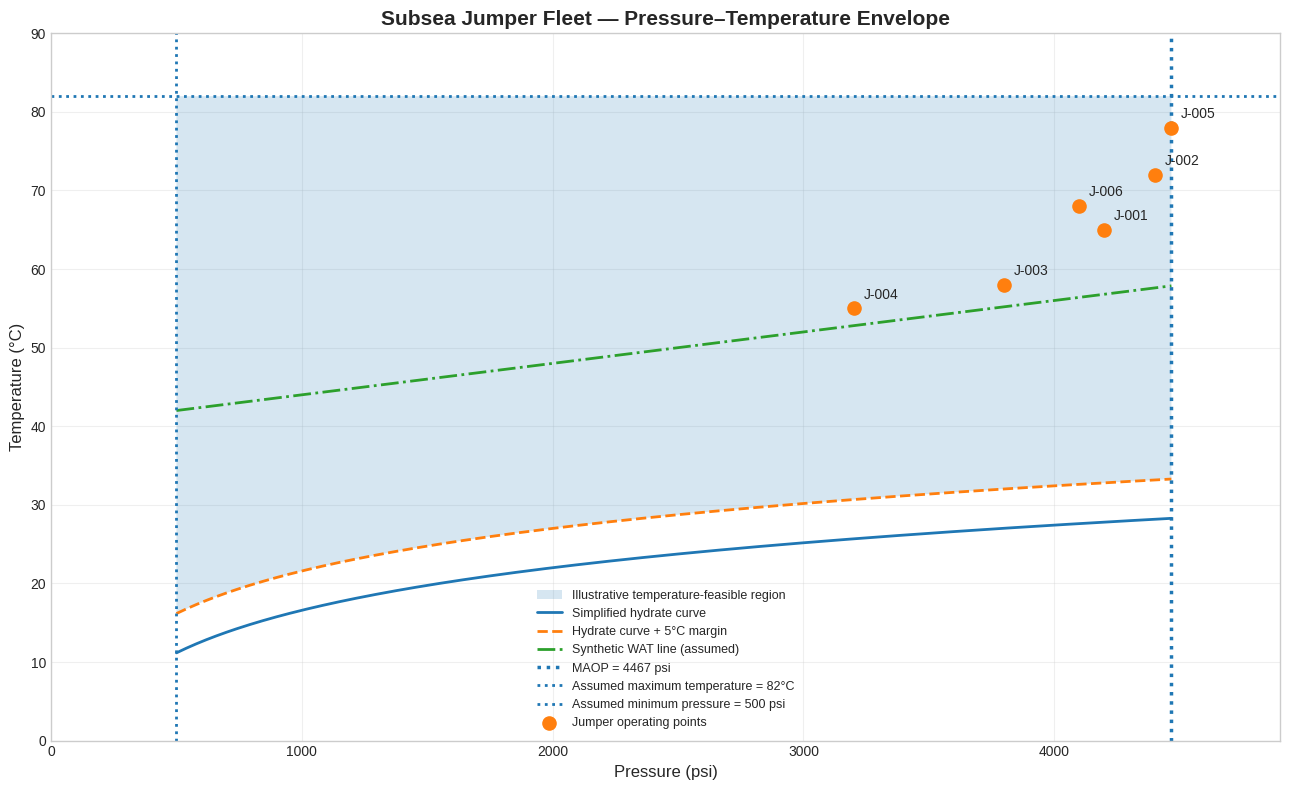


JUMPER OPERATING POINTS
----------------------------------------
J-001: Pressure = 4200 psi, Temperature = 65.0 °C
J-002: Pressure = 4400 psi, Temperature = 72.0 °C
J-003: Pressure = 3800 psi, Temperature = 58.0 °C
J-004: Pressure = 3200 psi, Temperature = 55.0 °C
J-005: Pressure = 4467 psi, Temperature = 78.0 °C
J-006: Pressure = 4100 psi, Temperature = 68.0 °C

Note: The WAT line and envelope limits are illustrative.
Confirm all boundaries using approved engineering data.


In [15]:

import numpy as np
import matplotlib.pyplot as plto

jumpers = ["J-001", "J-002", "J-003", "J-004", "J-005", "J-006"]

pressure = np.array([4200, 4400, 3800, 3200, 4467, 4100], dtype=float)
temperature = np.array([65, 72, 58, 55, 78, 68], dtype=flo

P_MIN = 500.0
MAOP = 4467.0
T_MAX = 82.0
HYDRATE_MARGIN = 5.0



p_curve = np.linspace(P_MIN, MAOP, 300)

hydrate_curve = 4.0 + 18.0 * np.log10(p_curve / 200.0)

hydrate_safe_boundary = hydrate_curve + HYDRATE_MARGIN

wat_line = 42.0 + 0.004 *
 (p_curve - P_MIN)



fig, ax = plt.subplots(figsize=(13, 8))



ax.fill_between(
    p_curve,
    hydrate_safe_boundary,
    T_MAX,
    where=(hydrate_safe_boundary <= T_MAX),
    alpha=0.18,
    label="Illustrative temperature-feasible region"
)


ax.plot(
    p_curve,
    hydrate_curve,
    linewidth=2,
    label="Simplified hydrate curve"
)

ax.plot(
    p_curve,
    hydrate_safe_boundary,
    linestyle="--",
    linewidth=2,
    label="Hydrate curve + 5°C margin"
)

ax.plot(
    p_curve,
    wat_line,
    linestyle="-.",
    linewidth=2,
    label="Synthetic WAT line (assumed)"
)


ax.axvline(
    x=MAOP,
    linestyle=":",
    linewidth=2.5,
    label=f"MAOP = {MAOP:.0f} psi"
)


ax.axhline(
    y=T_MAX,
    linestyle=":",
    linewidth=2,
    label=f"Assumed maximum temperature = {T_MAX:.0f}°C"
)

ax.axvline(
    x=P_MIN,
    linestyle=":",
    linewidth=2,
    label=f"Assumed minimum pressure = {P_MIN:.0f} psi"
)


ax.scatter(
    pressure,
    temperature,
    s=90,
    marker="o",
    zorder=5,
    label="Jumper operating points"
)

for jumper, p, t in zip(jumpers, pressure, temperature):
    ax.annotate(
        jumper,
        (p, t),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=10
    )


ax.set_xlabel("Pressure (psi)", fontsize=12)
ax.set_ylabel("Temperature (°C)", fontsize=12)

ax.set_title(
    "Subsea Jumper Fleet — Pressure–Temperature Envelope",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlim(0, 4900)
ax.set_ylim(0, 90)

ax.grid(True, alpha=0.3)
ax.legend(loc="best", fontsize=9)
plt.tight_layout()
plt.show


print("\nJUMPER OPERATING POINTS")
print("-" * 40)

for jumper, p, t in zip(jumpers, pressure, temperature):
    print(f"{jumper}: Pressure = {p:.0f} psi, Temperature = {t:.1f} °C")

print("\nNote: The WAT line and envelope limits are illustrative.")
print("Confirm all boundaries using approved engineering data.")


QUESTION 3

Extend to a 3-parameter envelope (P-T-flow rate) and create a 3D scatter plot showing operating points coloured by envelope status.


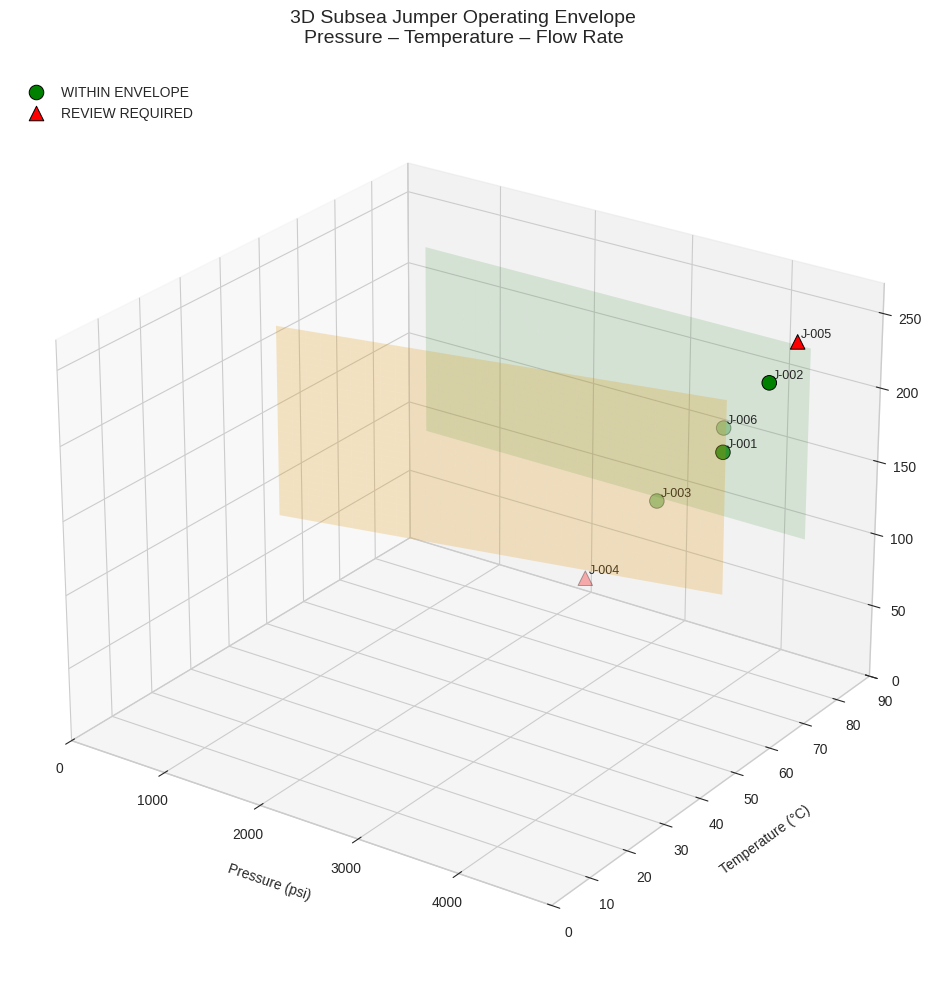


3D P-T-FLOW ENVELOPE SCREENING RESULTS


,Jumper,Pressure_psi,Temperature_C,Flow_m3_h,Minimum_Temperature_C,Envelope_Status
0,J-001,4200,65,180,56.80,WITHIN ENVELOPE
1,J-002,4400,72,220,57.60,WITHIN ENVELOPE
2,J-003,3800,58,150,55.20,WITHIN ENVELOPE
3,J-004,3200,55,90,52.80,REVIEW REQUIRED
4,J-005,4467,78,240,57.87,REVIEW REQUIRED
5,J-006,4100,68,190,56.40,WITHIN ENVELOPE



ASSUMED LIMITS
Minimum pressure: 500 psi
MAOP: 4467 psi
Maximum temperature: 82 °C
Flow range: 100–230 m³/h


In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.lines import Line2D

data = {
    "Jumper": ["J-001", "J-002", "J-003", "J-004", "J-005", "J-006"],
    "Pressure_psi": [4200, 4400, 3800, 3200, 4467, 4100],
    "Temperature_C": [65, 72, 58, 55, 78, 68],
    "Flow_m3_h": [180, 220, 150, 90, 240, 190]
}

df = pd.DataFrame(data)

P_MIN = 500.0
MAOP = 4467.0
T_MAX = 82.0
FLOW_MIN = 100.0
FLOW_MAX = 230.0
HYDRATE_MARGIN = 5.0

def hydrate_temperature(pressure_psi):
    pressure_psi = np.asarray(pressure_psi, dtype=float)
    return 4.0 + 18.0 * np.log10(pressure_psi / 200.0)

def synthetic_wat_temperature(pressure_psi):
    return 42.0 + 0.004 * (np.asarray(pressure_psi) - P_MIN)

def minimum_operating_temperature(pressure_psi):
    hydrate_limit = hydrate_temperature(pressure_psi) + HYDRATE_MARGIN
    wat_limit = synthetic_wat_temperature(pressure_psi)
    return np.maximum(hydrate_limit, wat_limit)

def classify_envelope_status(row):
    p = float(row["Pressure_psi"])
    t = float(row["Temperature_C"])
    q = float(row["Flow_m3_h"])

    pressure_ok = P_MIN <= p <= MAOP
    t_min = float(minimum_operating_temperature(p))
    temperature_ok = t_min <= t <= T_MAX
    flow_ok = FLOW_MIN <= q <= FLOW_MAX

    if pressure_ok and temperature_ok and flow_ok:
        return "WITHIN ENVELOPE"
    return "REVIEW REQUIRED"

df["Minimum_Temperature_C"] = minimum_operating_temperature(df["Pressure_psi"].to_numpy())
df["Envelope_Status"] = df.apply(classify_envelope_status, axis=1)

fig = plt.figure(figsize=(14, 10))
ax = fig.add_subplot(111, projection="3d")

p_grid = np.linspace(P_MIN, MAOP, 60)
q_grid = np.linspace(FLOW_MIN, FLOW_MAX, 30)
P, Q = np.meshgrid(p_grid, q_grid)

T_LOWER = minimum_operating_temperature(P)
T_UPPER = np.full_like(P, T_MAX)

ax.plot_surface(P, T_LOWER, Q, alpha=0.22, linewidth=0, color="orange")
ax.plot_surface(P, T_UPPER, Q, alpha=0.12, linewidth=0, color="green")

status_styles = {
    "WITHIN ENVELOPE": {"color": "green", "marker": "o"},
    "REVIEW REQUIRED": {"color": "red", "marker": "^"}
}

for status, style in status_styles.items():
    subset = df[df["Envelope_Status"] == status]
    ax.scatter(
        subset["Pressure_psi"],
        subset["Temperature_C"],
        subset["Flow_m3_h"],
        c=style["color"],
        marker=style["marker"],
        s=110,
        edgecolors="black",
        linewidths=0.7,
        label=status,
        depthshade=True
    )

for _, row in df.iterrows():
    ax.text(
        row["Pressure_psi"],
        row["Temperature_C"] + 1.0,
        row["Flow_m3_h"] + 2.0,
        row["Jumper"],
        fontsize=9
    )

ax.set_xlabel("Pressure (psi)", labelpad=12)
ax.set_ylabel("Temperature (°C)", labelpad=12)
ax.set_zlabel("Flow rate (m³/h)", labelpad=12)

ax.set_title(
    "3D Subsea Jumper Operating Envelope\nPressure – Temperature – Flow Rate",
    pad=22,
    fontsize=14
)

ax.set_xlim(0, 4900)
ax.set_ylim(0, 90)
ax.set_zlim(0, 270)

ax.legend(loc="upper left")
ax.view_init(elev=25, azim=-55)

plt.tight_layout()
plt.show()

print("\n3D P-T-FLOW ENVELOPE SCREENING RESULTS")
print("=" * 75)
display(df[["Jumper", "Pressure_psi", "Temperature_C", "Flow_m3_h", "Minimum_Temperature_C", "Envelope_Status"]].round(2))

print("\nASSUMED LIMITS")
print(f"Minimum pressure: {P_MIN:.0f} psi")
print(f"MAOP: {MAOP:.0f} psi")
print(f"Maximum temperature: {T_MAX:.0f} °C")
print(f"Flow range: {FLOW_MIN:.0f}–{FLOW_MAX:.0f} m³/h")

QUESTION 4

Write a function that takes a DataFrame of operating data and returns the percentage of time each parameter was within the design envelope.



In [37]:
import pandas as pd
import numpy as np

def percentage_within_envelope(
    df,
    pressure_min=500,
    pressure_max=4467,
    temperature_min=None,
    temperature_max=82,
    flow_min=100,
    flow_max=230
):


    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame.")

    if df.empty:
        raise ValueError("The DataFrame is empty.")

    required_columns = [
        "Pressure_psi",
        "Temperature_C",
        "Flow_m3_h"
    ]

    missing_columns = [
        col for col in required_columns
        if col not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing required columns: {missing_columns}"
        )

    limits = {
        "pressure_min": pressure_min,
        "pressure_max": pressure_max,
        "temperature_max": temperature_max,
        "flow_min": flow_min,
        "flow_max": flow_max
    }

    if temperature_min is not None:
        limits["temperature_min"] = temperature_min

    for name, value in limits.items():
        if (
            isinstance(value, (bool, np.bool_))
            or not isinstance(value, (int, float, np.number))
        ):
            raise TypeError(f"{name} must be numeric.")

        if not np.isfinite(value):
            raise ValueError(f"{name} must be finite.")

    if pressure_min < 0 or pressure_min >= pressure_max:
        raise ValueError("Invalid pressure limit constraints.")

    if temperature_min is not None and temperature_min >= temperature_max:
        raise ValueError("Invalid temperature limit constraints.")

    if flow_min < 0 or flow_min >= flow_max:
        raise ValueError("Invalid flow rate limit constraints.")

    if temperature_min is None:
        pressure_values = pd.to_numeric(
            df["Pressure_psi"], errors="coerce"
        )

        hydrate_limit = (
            4.0 + 18.0 * np.log10(
                pressure_values.where(pressure_values > 0) / 200.0
            ) + 5.0
        )

        wat_limit = 42.0 + 0.004 * (pressure_values - 500.0)

        temperature_lower_limit = pd.Series(
            np.maximum(hydrate_limit, wat_limit),
            index=df.index
        )
    else:
        temperature_lower_limit = pd.Series(
            temperature_min, index=df.index, dtype=float
        )

    data = df[required_columns].apply(
        pd.to_numeric, errors="coerce"
    )

    data = data.replace([np.inf, -np.inf], np.nan)

    pressure = data["Pressure_psi"]
    temperature = data["Temperature_C"]
    flow = data["Flow_m3_h"]

    pressure_valid = pressure.notna()
    temperature_valid = (
        temperature.notna()
        & temperature_lower_limit.notna()
    )
    flow_valid = flow.notna()

    pressure_within = (
        pressure_valid
        & pressure.between(pressure_min, pressure_max)
    )

    temperature_within = (
        temperature_valid
        & (temperature > temperature_lower_limit)
        & (temperature <= temperature_max)
    )

    flow_within = (
        flow_valid
        & flow.between(flow_min, flow_max)
    )

    def calculate_percentage(within, valid):
        if valid.sum() == 0:
            return np.nan
        return 100 * within.sum() / valid.sum()

    pressure_pct = calculate_percentage(
        pressure_within, pressure_valid
    )

    temperature_pct = calculate_percentage(
        temperature_within, temperature_valid
    )

    flow_pct = calculate_percentage(
        flow_within, flow_valid
    )

    all_valid = (
        pressure_valid
        & temperature_valid
        & flow_valid
    )

    all_within = (
        pressure_within
        & temperature_within
        & flow_within
    )

    overall_pct = calculate_percentage(all_within, all_valid)

    summary = pd.DataFrame({
        "Parameter": [
            "Pressure",
            "Temperature",
            "Flow rate",
            "All parameters combined"
        ],
        "Valid observations": [
            int(pressure_valid.sum()),
            int(temperature_valid.sum()),
            int(flow_valid.sum()),
            int(all_valid.sum())
        ],
        "Within envelope (%)": [
            pressure_pct,
            temperature_pct,
            flow_pct,
            overall_pct
        ]
    })

    return summary

operating_data = pd.DataFrame({
    "Pressure_psi": [4200, 4400, 3800, 3200, 4467, 4100],
    "Temperature_C": [65, 72, 58, 55, 78, 68],
    "Flow_m3_h": [180, 220, 150, 90, 240, 190]
})

try:
    result = percentage_within_envelope(operating_data)

    print("PERCENTAGE OF OPERATING DATA WITHIN ENVELOPE")
    print("=" * 55)
    print(result.to_string(index=False, float_format=lambda x: f"{x:.2f}"))

except (TypeError, ValueError) as error:
    print("Input error:", error)

PERCENTAGE OF OPERATING DATA WITHIN ENVELOPE
              Parameter  Valid observations  Within envelope (%)
               Pressure                   6               100.00
            Temperature                   6               100.00
              Flow rate                   6                66.67
All parameters combined                   6                66.67
